In [1]:
import numpy as np
from itertools import product
from scipy.linalg import expm

def unitary_to_ptm(unitary: np.ndarray) -> np.ndarray:
    """
    Converts a unitary matrix to its corresponding Pauli Transfer Matrix (PTM).
    Assumes the input is a 2-qubit unitary (i.e., 4x4 matrix).
    
    Args:
        unitary (np.ndarray): A 4x4 unitary matrix.

    Returns:
        np.ndarray: A 16x16 Pauli Transfer Matrix (PTM).
    """
    # Check input
    dim = unitary.shape[0]
    assert unitary.shape == (dim, dim), "Unitary must be square."
    assert np.allclose(unitary @ unitary.conj().T, np.eye(dim)), "Input must be unitary."
    assert dim == 4, "Function currently supports only 2-qubit (4x4) unitaries."

    # Define single-qubit Pauli matrices
    I = np.eye(2, dtype=complex)
    X = np.array([[0, 1], [1, 0]], dtype=complex)
    Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
    Z = np.array([[1, 0], [0, -1]], dtype=complex)
    paulis = [I, X, Y, Z]

    # Build 2-qubit Pauli basis: tensor products
    basis = [np.kron(p1, p2) for p1, p2 in product(paulis, repeat=2)]
    basis = np.array(basis)  # shape (16, 4, 4)

    # Compute PTM: PTM[i,j] = (1/dim) * Tr[Pi† U Pj U†]
    ptm = np.zeros((16, 16), dtype=complex)
    for i, Pi in enumerate(basis):
        for j, Pj in enumerate(basis):
            transformed = unitary @ Pj @ unitary.conj().T
            ptm[j, i] = np.trace(Pi.conj().T @ transformed) / dim

    # Ensure result is real
    assert np.abs(ptm.imag).max() < 1e-10, "PTM has significant imaginary parts."
    return ptm.real


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patches as mpatches
import matplotlib
from fractions import Fraction
from itertools import product

# --- Filename helper ---
def filename_label(phi):
    frac = Fraction(phi / np.pi).limit_denominator(8)
    num, den = frac.numerator, frac.denominator
    if num == 0:
        return "0"
    if den == 1:
        return "pi" if num == 1 else f"{num}pi"
    if num == 1:
        return f"pi_over_{den}"
    return f"{num}pi_over_{den}"

# --- Unitaries ---
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
I = np.eye(2)
H = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])
S = np.array([[1, 0], [0, 1j]])
S_dagger = S.conj().T

def zz_unitary(phi):
    return np.diag([
        np.exp(-1j * phi / 2),
        np.exp(1j * phi / 2),
        np.exp(1j * phi / 2),
        np.exp(-1j * phi / 2),
    ])

def dme_heisenberg(phi):
    ZZ_phi = zz_unitary(phi)
    YY_phi = (
        np.kron(S_dagger, I) @ np.kron(H, I) @
        np.kron(I, S_dagger) @ np.kron(I, H) @
        zz_unitary(phi) @
        np.kron(H, I) @ np.kron(S, I) @
        np.kron(I, H) @ np.kron(I, S)
    )
    XX_phi = (
        np.kron(H, I) @ np.kron(I, H) @
        zz_unitary(phi) @
        np.kron(H, I) @ np.kron(I, H)
    )
    return ZZ_phi @ YY_phi @ XX_phi

# --- PTM labels ---
pauli_labels_1q = ['I', 'X', 'Y', 'Z']
ptm_labels = [a + b for a, b in product(pauli_labels_1q, repeat=2)]

# --- Plotting helper ---
def plot_process_matrix_colormap(m: np.ndarray, basis_labels, ax=None, title=None, cmap='RdBu_r'):
    nx, ny = m.shape
    if ax is None:
        fig, ax = plt.subplots()
    ax.axis("scaled")
    ax.patch.set_facecolor("white")
    mflat = m.flatten()
    vals = np.real(mflat)
    mags = np.abs(mflat) ** 0.5
    norm = Normalize(vmin=-1, vmax=1)
    colors = plt.get_cmap(cmap)(norm(vals))
    idx = 0
    for ix in range(nx):
        for iy in range(ny):
            ax.add_artist(
                mpatches.RegularPolygon(
                    xy=(ix, iy),
                    numVertices=4,
                    orientation=np.pi / 4,
                    color=colors[idx],
                    radius=2.0 ** -0.5 * mags[idx],
                    linewidth=0.0,
                )
            )
            idx += 1
    ax.set_xticks(np.arange(nx))
    ax.set_xticklabels(basis_labels, rotation=90)
    ax.set_yticks(np.arange(ny))
    ax.set_yticklabels(basis_labels)
    ax.set_xlim(-0.5, nx - 0.5)
    ax.set_ylim(-0.5, ny - 0.5)
    ax.grid(False)
    if title:
        ax.set_title(title)

def RZ(phi):
    return expm(-1j * phi * Z)

def RX(theta):
    return expm(-1j * theta * X)

def RY(theta):
    return expm(-1j * theta * Y)

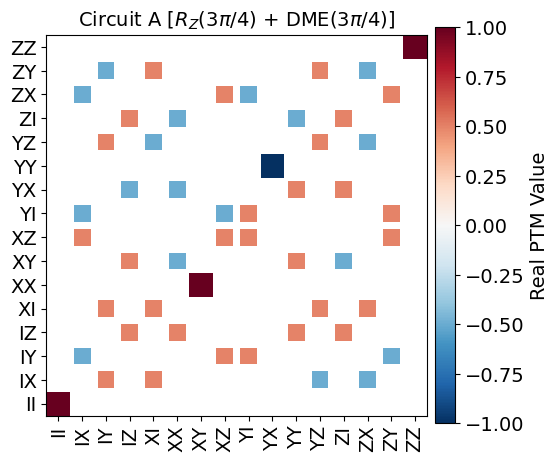

Saved ideal DME PTM plot for θ=2.356 to Ideal_DME_phi_3pi_over_4_ptm.png


In [3]:
# --- Plot ideal PTMs ---
phi_list = [3*np.pi/4]

for phi_target in phi_list:
    ptm_ideal = unitary_to_ptm(dme_heisenberg(phi_target)@ np.kron(I, RZ(phi_target)))

    matplotlib.rcParams.update({
        "text.usetex": False,
        "font.size": 14,
        "axes.titlesize": 14,
        "axes.labelsize": 14,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 14,
        "figure.titlesize": 14,
    })

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    plot_process_matrix_colormap(
        ptm_ideal,
        ptm_labels,
        ax=ax,
        title=r"Circuit A [$R_Z(3\pi/4)$ + DME($3\pi/4$)]",
    )

    plt.tight_layout()
    sm = ScalarMappable(norm=Normalize(vmin=-1, vmax=1), cmap='RdBu_r')
    sm.set_array([])
    cbar = fig.colorbar(
        sm,
        ax=ax,
        location='right',
        fraction=0.08,
        pad=0.02,
    )
    cbar.set_label("Real PTM Value", fontsize=14)
    cbar.ax.tick_params(labelsize=14)

    fname_label = filename_label(phi_target)
    fname = f"Ideal_DME_phi_{fname_label}_ptm.png"
    plt.savefig(fname, dpi=600, bbox_inches='tight')
    plt.show()
    print(f"Saved ideal DME PTM plot for θ={phi_target:.3f} to {fname}")


In [4]:
def ptrace(matrix, index=1, n1=2, n2=2):
    """Partial trace over one subsystem."""
    current_tensor = matrix.reshape([n1, n2, n1, n2])
    if index == 1:
        return np.trace(current_tensor, axis1=1, axis2=3)
    elif index == 2:
        return np.trace(current_tensor, axis1=0, axis2=2)
    else:
        print('Error')

In [5]:
psi0 = np.array([[1, 0], [0, 0]])

In [ ]:
import numpy as np

def shift_y_by_delta(theta_list, y_val, delta):
    """
    Shift y_val to correspond to theta_list + delta (mod π),
    preserving original values without interpolation.

    Parameters:
    - theta_list: np.ndarray, original theta values (non-uniform)
    - y_val: np.ndarray, corresponding y values
    - delta: float, shift value in radians

    Returns:
    - shifted_y_val: np.ndarray, y values permuted to match theta + delta wrapped into [-π/2, π/2]
    """
    # Shift and wrap theta into [-π/2, π/2]
    wrapped_theta = ((theta_list + delta + np.pi/2) % np.pi) - np.pi/2

    # Sort by wrapped theta and reorder y accordingly
    sort_idx = np.argsort(wrapped_theta)
    wrapped_theta_sorted = wrapped_theta[sort_idx]
    reordered_y = y_val[sort_idx]

    return reordered_y


In [42]:
import pandas as pd
import numpy as np

# Define numeric theta_X manually
theta_X = np.array([
    -np.pi/8, -np.pi/5, -2*np.pi/7, -2*np.pi/5, -np.pi/2,
    -3*np.pi/5, -5*np.pi/7, -4*np.pi/5, -7*np.pi/8, -np.pi,
    0,
    np.pi/8, np.pi/5, 2*np.pi/7, 2*np.pi/5, np.pi/2,
    3*np.pi/5, 5*np.pi/7, 4*np.pi/5, 7*np.pi/8, np.pi
])

# Get sort indices and sort theta_X
sorted_indices = np.argsort(theta_X)
theta_X = theta_X[sorted_indices]

# Define suffix
suffix = "Z0"
# Load data
df = pd.read_csv("energy_values_A_" + suffix + ".csv", sep=",")  # or sep="," if needed

# Extract and sort each energy column, assign to globals with suffix
for col in ['E1_ideal', 'E2_ideal', 'E1_meas', 'E2_meas']:
    globals()[f"{col}_{suffix}"] = df[col].to_numpy()[sorted_indices]
    print(f"{col}_{suffix}")

# Define suffix
suffix = "Z4"
# Load data
df = pd.read_csv("energy_values_A_" + suffix + ".csv", sep=",")  # or sep="," if needed

# Extract and sort each energy column, assign to globals with suffix
for col in ['E1_ideal', 'E2_ideal', 'E1_meas', 'E2_meas']:
    globals()[f"{col}_{suffix}"] = df[col].to_numpy()[sorted_indices]
    print(f"{col}_{suffix}")

# Define suffix
suffix = "Z8"
# Load data
df = pd.read_csv("energy_values_A_" + suffix + ".csv", sep=",")  # or sep="," if needed

# Extract and sort each energy column, assign to globals with suffix
for col in ['E1_ideal', 'E2_ideal', 'E1_meas', 'E2_meas']:
    globals()[f"{col}_{suffix}"] = df[col].to_numpy()[sorted_indices]
    print(f"{col}_{suffix}")

E1_ideal_Z0
E2_ideal_Z0
E1_meas_Z0
E2_meas_Z0
E1_ideal_Z4
E2_ideal_Z4
E1_meas_Z4
E2_meas_Z4
E1_ideal_Z8
E2_ideal_Z8
E1_meas_Z8
E2_meas_Z8


In [43]:
theta_X

array([-3.14159265, -2.74889357, -2.51327412, -2.24399475, -1.88495559,
       -1.57079633, -1.25663706, -0.8975979 , -0.62831853, -0.39269908,
        0.        ,  0.39269908,  0.62831853,  0.8975979 ,  1.25663706,
        1.57079633,  1.88495559,  2.24399475,  2.51327412,  2.74889357,
        3.14159265])

d:\Program Files\python\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Program Files\python\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(-1.1, 1.1)

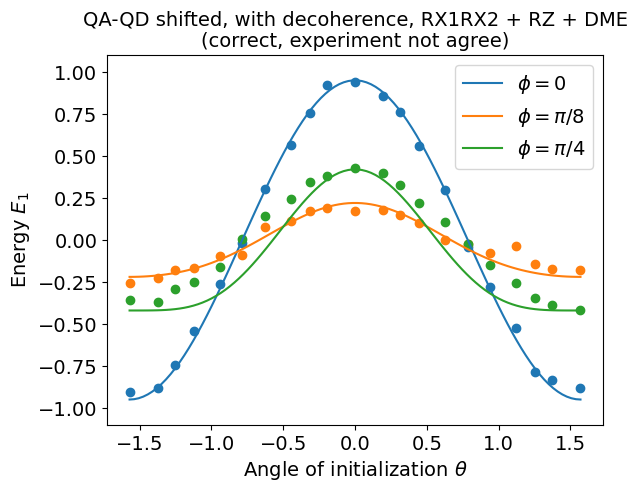

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [dme_heisenberg(phi) @ np.kron(I, RZ(phi)) @ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    if idx==0:
        final_matrices = [apply_depolarizing_noise(matrix,0.05) for matrix in final_matrices]
    elif idx==1:
        final_matrices = [apply_depolarizing_noise(matrix,0.78) for matrix in final_matrices]
    elif idx==2:
        final_matrices = [apply_depolarizing_noise(matrix,0.58) for matrix in final_matrices]

    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]

    # Compute energy values
    energy_init = [system[0][0] - system[1][1] for system in original_system]
    energy_1 = [system[0][0] - system[1][1] for system in subsystem_1]
    
    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_1), label=r'$\phi =$' + phi_name[idx])

plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z0,0.18))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z8,-0.5))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z4,-0.1))


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
plt.title('QA-QD shifted, with decoherence, RX1RX2 + RZ + DME\n(correct, experiment not agree)')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Energy $E_1$')
plt.ylim([-1.1,1.1])

(-1.1, 1.1)

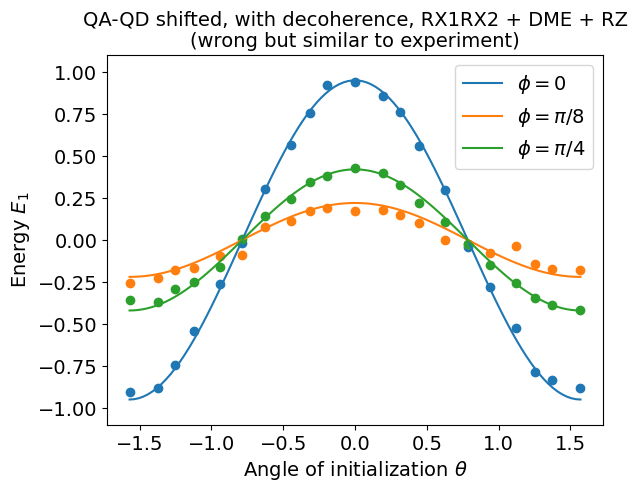

In [101]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    if idx==0:
        final_matrices = [apply_depolarizing_noise(matrix,0.05) for matrix in final_matrices]
    elif idx==1:
        final_matrices = [apply_depolarizing_noise(matrix,0.78) for matrix in final_matrices]
    elif idx==2:
        final_matrices = [apply_depolarizing_noise(matrix,0.58) for matrix in final_matrices]

    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]

    # Compute energy values
    energy_init = [system[0][0] - system[1][1] for system in original_system]
    energy_1 = [system[0][0] - system[1][1] for system in subsystem_1]
    
    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_1), label=r'$\phi =$' + phi_name[idx])

plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z0,0.18))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z8,-0.5))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z4,-0.1))


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
plt.title('QA-QD shifted, with decoherence, RX1RX2 + DME + RZ\n(wrong but similar to experiment)')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Energy $E_1$')
plt.ylim([-1.1,1.1])

(-1.1, 1.1)

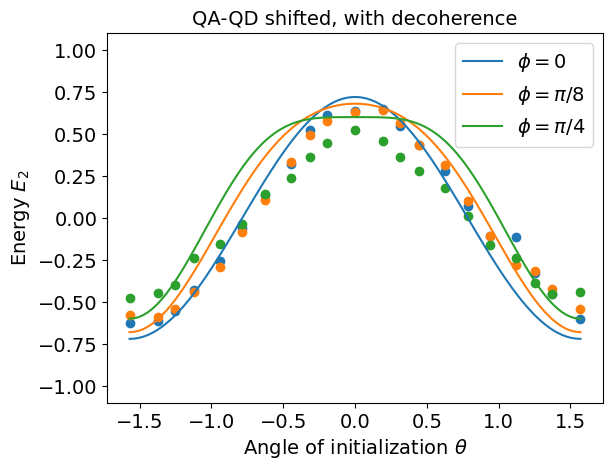

In [64]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [dme_heisenberg(phi) @ np.kron(I, RZ(phi)) @ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    if idx==0:
        final_matrices = [apply_depolarizing_noise(matrix,0.28) for matrix in final_matrices]
    elif idx==1:
        final_matrices = [apply_depolarizing_noise(matrix,0.32) for matrix in final_matrices]
    elif idx==2:
        final_matrices = [apply_depolarizing_noise(matrix,0.4) for matrix in final_matrices]

    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]

    # Compute energy values
    energy_init = [system[0][0] - system[1][1] for system in original_system]
    energy_2 = [system[0][0] - system[1][1] for system in subsystem_2]
    
    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_2), label=r'$\phi =$' + phi_name[idx])

plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E2_meas_Z0,0.18-np.pi/4))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E2_meas_Z8,-0.4))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E2_meas_Z4,-0.0000000000000003))


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
plt.title('QA-QD shifted, with decoherence')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Energy $E_2$')
plt.ylim([-1.1,1.1])

Text(0, 0.5, 'Total Energy')

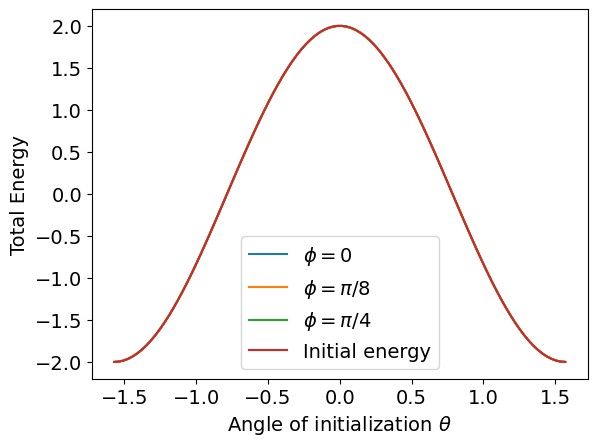

In [81]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [np.kron(I, RZ(phi)) @ dme_heisenberg(phi) @ np.kron(I, RZ(phi)) @ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]
    
    
    # Compute energy values
    energy_1 = [system[0][0] - system[1][1] for system in subsystem_1]
    energy_2 = [system[0][0] - system[1][1] for system in subsystem_2]
    energy_init = [system[0][0] - system[1][1] for system in original_system]

    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_1) + np.array(energy_2), label=r'$\phi =$' + phi_name[idx])
plt.plot(theta_list, np.array(energy_init)*2, label = "Initial energy")

# plt.scatter(theta_X/2,E2_meas_Z0)
# plt.scatter(theta_X/2,E2_meas_Z8)
# plt.scatter(theta_X/2,E2_meas_Z4)


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Total Energy')
# plt.ylim([-1.1,1.1])

E1_ideal_Z0
E2_ideal_Z0
E1_meas_Z0
E2_meas_Z0
E1_ideal_Z4
E2_ideal_Z4
E1_meas_Z4
E2_meas_Z4
E1_ideal_Z8
E2_ideal_Z8
E1_meas_Z8
E2_meas_Z8


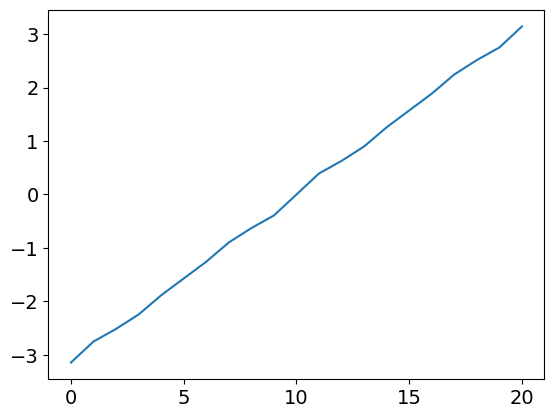

In [ ]:
plt.plot(theta_X_sorted)

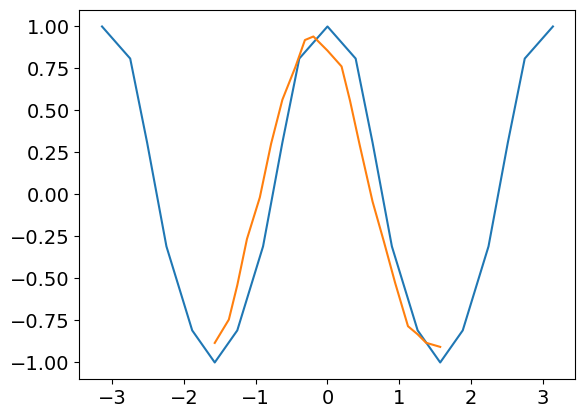

In [ ]:
plt.plot(theta_X_sorted,E1_ideal_Z0_sorted)
plt.plot(theta_X_sorted/2,E1_meas_Z0_sorted)
# plt.plot(theta_X,E2_ideal)

In [ ]:
# Add depolarizing noise to the density matrix
def apply_depolarizing_noise(rho, p=0.5):
    dim = rho.shape[0]
    identity = np.eye(dim)
    return (1 - p) * rho + (p / dim) * identity

def apply_bitflip_error(state, p=0.7):
    return 0.2*(RX(np.pi/2) @ state) + 0.8*state if np.random.rand() < p else state

def apply_dephasing_noise(rho, p=0.5):
    return (1 - p) * rho + p * Z@rho@Z  # Dephasing noise

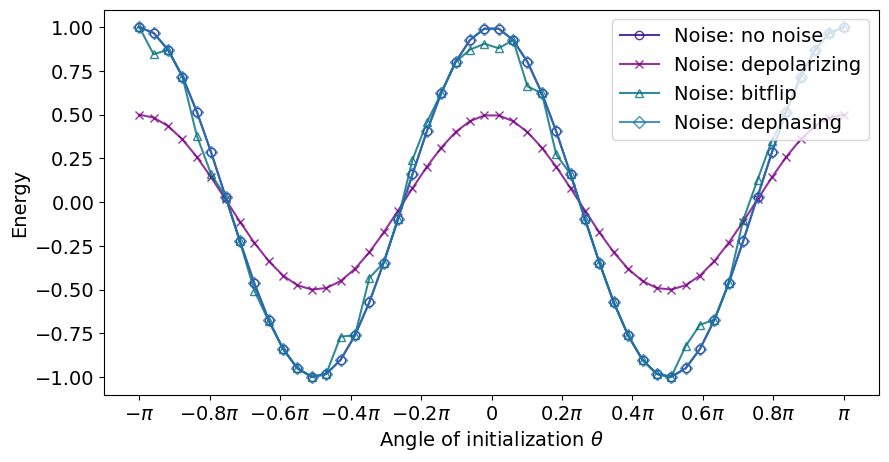

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the parameters
theta_list = np.linspace(-np.pi, np.pi, 50)
noise_types = ['no noise', 'depolarizing', 'bitflip', 'dephasing']  # Noise models to check

# Define custom colors and markers
color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o', 'x', '^', 'D']

plt.figure(figsize=[10,5])

# Loop over each noise model and compute the energy
for idx, noise_type in enumerate(noise_types):
    energy_list = []
    
    # Loop over each angle for theta
    for theta in theta_list:
        # Initial system without noise
        original_system = RX(theta) @ psi0 @ RX(-theta)
        
        # Apply noise based on the selected noise model
        if noise_type == 'no noise':
            final_state = original_system
        elif noise_type == 'depolarizing':
            final_state = apply_depolarizing_noise(original_system)
        elif noise_type == 'bitflip':
            final_state = apply_bitflip_error(original_system)
        elif noise_type == 'dephasing':
            final_state = apply_dephasing_noise(original_system)

        # Compute energy for the final state
        energy = final_state[0][0] - final_state[1][1]
        energy_list.append(energy)

    # Plot the results for the current noise model with custom color and marker
    plt.plot(theta_list, energy_list, label=f'Noise: {noise_type}', color=color[idx], marker=markers[idx], markerfacecolor='none', alpha=0.8)

# Display the plot
plt.legend(loc='upper right')

plt.xlabel(r'Angle of initialization $\theta$')
plt.ylabel(r'Energy')
plt.ylim([-1.1, 1.1])

# Custom ticks and labels
ticks = np.linspace(-np.pi, np.pi, 11)
tick_labels = [
    r'$-\pi$', r'$-0.8\pi$', r'$-0.6\pi$', r'$-0.4\pi$', r'$-0.2\pi$',
    r'$0$', 
    r'$0.2\pi$', r'$0.4\pi$', r'$0.6\pi$', r'$0.8\pi$', r'$\pi$'
]
plt.xticks(ticks, tick_labels)

plt.show()


d:\Program Files\python\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Program Files\python\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


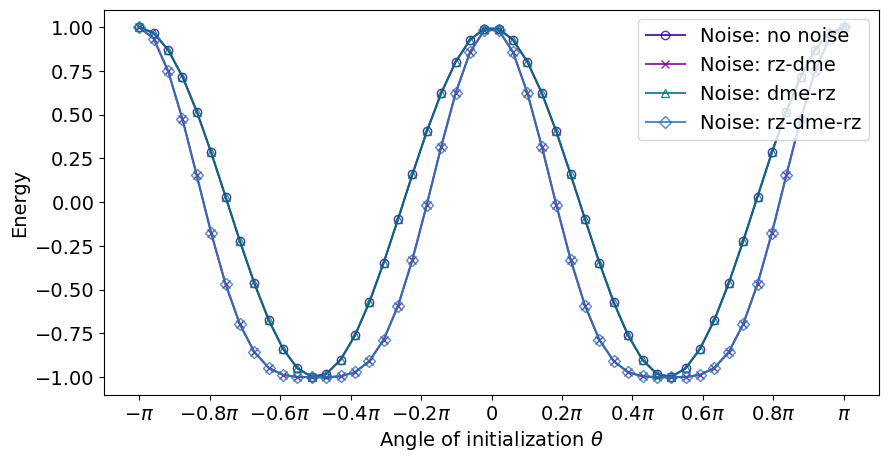

In [97]:
import numpy as np
import matplotlib.pyplot as plt

# Define the parameters
theta_list = np.linspace(-np.pi, np.pi, 50)
noise_types = ['no noise', 'rz-dme', 'dme-rz', 'rz-dme-rz']  # Noise models to check

# Define custom colors and markers
color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o', 'x', '^', 'D']

plt.figure(figsize=[10,5])
phi = np.pi/4
# Loop over each noise model and compute the energy
for idx, noise_type in enumerate(noise_types):
    energy_list = []
    
    # Loop over each angle for theta
    for theta in theta_list:
        # Initial system without noise
        original_system = RX(theta) @ psi0 @ RX(-theta)
        original_system =  np.kron(original_system,original_system)

        # Apply noise based on the selected noise model
        if noise_type == 'no noise':
            U = np.kron(I,I)
        elif noise_type == 'dme-rz':
            U = np.kron(I, RZ(phi)) @ dme_heisenberg(phi)
        elif noise_type == 'rz-dme':
            U = dme_heisenberg(phi) @ np.kron(I, RZ(phi))
        elif noise_type == 'rz-dme-rz':
            U = np.kron(I, RZ(phi)) @ dme_heisenberg(phi) @ np.kron(I, RZ(phi))

        final_state = U @ original_system @ U.conj().T
        final_state = ptrace(final_state)
        # Compute energy for the final state
        energy = final_state[0][0] - final_state[1][1]
        energy_list.append(energy)

    # Plot the results for the current noise model with custom color and marker
    plt.plot(theta_list, energy_list, label=f'Noise: {noise_type}', color=color[idx], marker=markers[idx], markerfacecolor='none', alpha=0.8)

# Display the plot
plt.legend(loc='upper right')

plt.xlabel(r'Angle of initialization $\theta$')
plt.ylabel(r'Energy')
plt.ylim([-1.1, 1.1])

# Custom ticks and labels
ticks = np.linspace(-np.pi, np.pi, 11)
tick_labels = [
    r'$-\pi$', r'$-0.8\pi$', r'$-0.6\pi$', r'$-0.4\pi$', r'$-0.2\pi$',
    r'$0$', 
    r'$0.2\pi$', r'$0.4\pi$', r'$0.6\pi$', r'$0.8\pi$', r'$\pi$'
]
plt.xticks(ticks, tick_labels)

plt.show()


In [66]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patches as mpatches
from scipy.linalg import expm
import matplotlib
from fractions import Fraction
from qutip import Qobj  # << added import for Qobj
import pandas as pd
# Initialize data structure
energy_data = {}  # {theta_ZZ: {theta_X: [E1_ideal, E2_ideal, E1_meas, E2_meas]}}
# --- Filename helper as before ---
def filename_label(theta):
    # express theta/π as a simple fraction
    frac = Fraction(theta/np.pi).limit_denominator(8)
    num, den = frac.numerator, frac.denominator
    if num == 0:
        return "0"
    if den == 1:
        return "pi" if num == 1 else f"{num}pi"
    if num == 1:
        return f"pi_over_{den}"
    return f"{num}pi_over_{den}"
# --- DME ideal-unitary definition ---
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
I = np.eye(2)
H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
S = np.array([[1, 0], [0, 1j]])
S_dagger = S.conj().T
def zz_unitary(theta):
    return np.diag([
        np.exp(-1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(-1j * theta / 2),
    ])
def dme_heisenberg(phi):
    ZZ_phi = zz_unitary(phi)
    YY_phi = (
        np.kron(S_dagger, I) @ np.kron(H, I) @
        np.kron(I, S_dagger) @ np.kron(I, H) @
        zz_unitary(phi) @
        np.kron(H, I) @ np.kron(S, I) @
        np.kron(I, H) @ np.kron(I, S)
    )
    XX_phi = (
        np.kron(H, I) @ np.kron(I, H) @
        zz_unitary(phi) @
        np.kron(H, I) @ np.kron(I, H)
    )
    return ZZ_phi @ YY_phi @ XX_phi
# --- Single-qubit RZ ---
def RZ(phi):
    return expm(-1j * phi * Z)
def RX(phi):
    return expm(-1j * phi * X)
# --- PTM fidelity helper ---
def entanglement_fidelity(ptm_meas, ptm_ideal):
    dim = ptm_meas.shape[0]
    return np.real(np.trace(ptm_ideal.conj().T @ ptm_meas) / dim)
# --- Plotting helper ---
def plot_process_matrix_colormap(m: np.ndarray, basis_labels, ax=None, title=None, cmap='RdBu_r'):
    nx, ny = m.shape
    if ax is None:
        fig, ax = plt.subplots()
    ax.axis("scaled")
    ax.patch.set_facecolor("white")
    mflat = m.flatten()
    vals = np.real(mflat)
    mags = np.abs(mflat) ** 0.5
    norm = Normalize(vmin=-1, vmax=1)
    colors = plt.get_cmap(cmap)(norm(vals))
    idx = 0
    for ix in range(nx):
        for iy in range(ny):
            ax.add_artist(
                mpatches.RegularPolygon(
                    xy=(ix, iy),
                    numVertices=4,
                    orientation=np.pi / 4,
                    color=colors[idx],
                    radius=2.0 ** -0.5 * mags[idx],
                    linewidth=0.0,
                )
            )
            idx += 1
    ax.set_xticks(np.arange(nx))
    ax.set_xticklabels(basis_labels, rotation=90)
    ax.set_yticks(np.arange(ny))
    ax.set_yticklabels(basis_labels)
    ax.set_xlim(-0.5, nx - 0.5)
    ax.set_ylim(-0.5, ny - 0.5)
    ax.grid(False)
    if title:
        ax.set_title(title)
def ptm_z_expectation(ptm, basis_labels, qubit_index):
    if qubit_index == 1:
        label = "ZI"
    elif qubit_index == 2:
        label = "IZ"
    else:
        raise ValueError("qubit_index must be 1 or 2")
    try:
        idx = basis_labels.index(label)
    except ValueError:
        raise ValueError(f"{label} not found in PTM basis labels: {basis_labels}")
    return np.real(ptm[idx, idx])
# --- Your two lists of thetas ---
# theta_list = [0, np.pi/8, np.pi/4, np.pi/2]     # existing list
# theta_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]     # existing list
theta_list = [0, np.pi/8, np.pi/4]
# theta_list_X = [i * 0.05 * np.pi for i in range(-20, 21)]
theta_list_X = [-0.1*np.pi, -0.2*np.pi, -0.3*np.pi, -0.4*np.pi, -0.5*np.pi, -0.6*np.pi, -0.7*np.pi, -0.8*np.pi, -0.9*np.pi, -np.pi,
                0, 0.1*np.pi, 0.2*np.pi, 0.3*np.pi, 0.4*np.pi, 0.5*np.pi, 0.6*np.pi, 0.7*np.pi, 0.8*np.pi, 0.9*np.pi, np.pi]
# theta_list_X = [-0.1*np.pi, -0.2*np.pi, -0.3*np.pi, -0.4*np.pi, -0.5*np.pi,
#                 0, 0.1*np.pi, 0.2*np.pi, 0.3*np.pi, 0.4*np.pi, 0.5*np.pi]          # <-- fill in your other θ values here
# Loop over both lists
for theta_target_X in theta_list_X:
    for theta_target in theta_list:
        # compute pulse width and params_ZZ
        def get_width_for_rotation(p, th):
            return p['width'] * (th / (np.pi / 2))
        width = get_width_for_rotation(params_working, theta_target)
        params_ZZ = params_working.copy()
        params_ZZ['width'] = width
        print(f"{width} µs")
        # build CZ pulse and extract zz_gate
        c2_q1_q2 = prims.build_CZ_stark_from_parameters(
            control_q=duts_dict['Q1'],
            target_q=duts_dict['Q2'],
            **params_ZZ
        )
        zz_gate = c2_q1_q2.get_zzm_without_pi()
        # define single-qubit rotations
        s_both       = c1_q1.z(-np.pi/2) * c1_q2.z(-np.pi/2)
        s_dag_both   = c1_q1.z(np.pi/2)  * c1_q2.z(np.pi/2)
        h_both       = c1_q1.hadamard() * c1_q2.hadamard()
        RX_both      = c1_q1.x(-np.pi/2) * c1_q2.x(-np.pi/2)
        RX_dag_both  = c1_q1.x(np.pi/2)  * c1_q2.x(np.pi/2)
        RY_both      = c1_q1.y(-np.pi/2) * c1_q2.y(-np.pi/2)
        RY_dag_both  = c1_q1.y(np.pi/2)  * c1_q2.y(np.pi/2)
        R_z_po       = c1_q2.z(np.pi/4)
        R_z_ne       = c1_q2.z(-np.pi/4)
        R_x_q1       = c1_q1.x(theta_target_X)
        R_x_q2       = c1_q2.x(theta_target_X)
        # DME pulse block
        lpb_DME = (
            h_both + h_both + R_x_q1 * R_x_q2 +
            R_z_ne + zz_gate +
            RX_dag_both + zz_gate + RX_both +
            RY_dag_both + zz_gate + RY_both
        )
        # run tomography
        ProcessT = MultiQubitsProcessTomography(
            duts=[duts_dict['Q1'], duts_dict['Q2']],
            lpb=lpb_DME,
            measurement_mitigation=True,
        )
        ptm_meas = ProcessT.ptm
        basis    = ProcessT.model._basis
        labels   = basis.basis_name
        # ideal PTM via RX + DME + extra RZ on qubit 2
        U_ideal   =  Qobj(np.kron(RX(theta_target_X), RX(theta_target_X)) @ dme_heisenberg(theta_target) @ np.kron(I, RZ(np.pi/4)))
        ptm_ideal = basis.unitary_to_ptm(U_ideal.full())
        E1_ideal = ptm_z_expectation(ptm_ideal, labels, 1)
        E2_ideal = ptm_z_expectation(ptm_ideal, labels, 2)
        E1_meas  = ptm_z_expectation(ptm_meas,  labels, 1)
        E2_meas  = ptm_z_expectation(ptm_meas,  labels, 2)
        # Convert angles to labels (for indexing)
        theta_ZZ_label = filename_label(theta_target)
        theta_X_label = filename_label(theta_target_X)
        if theta_ZZ_label not in energy_data:
            energy_data[theta_ZZ_label] = {}
        energy_data[theta_ZZ_label][theta_X_label] = [E1_ideal, E2_ideal, E1_meas, E2_meas]
        # compute fidelity
        Fe  = entanglement_fidelity(ptm_meas, ptm_ideal)
        Fid = (4 * Fe + 1) / 5
        # plotting style
        matplotlib.rcParams.update({
            "text.usetex": False,
            "font.size": 22,
            "axes.titlesize": 22,
            "axes.labelsize": 22,
            "xtick.labelsize": 22,
            "ytick.labelsize": 22,
            "legend.fontsize": 22,
            "figure.titlesize": 22,
        })
        # plot measured vs. ideal
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
        plot_process_matrix_colormap(
        ptm_meas,
        labels,
        ax=ax1,
        title=f"Measured PTM\n$E_1$ = {E1_meas:.2f}, $E_2$ = {E2_meas:.2f}"
        )
        plot_process_matrix_colormap(
        ptm_ideal,
        labels,
        ax=ax2,
        title=f"Ideal PTM\n$E_1$ = {E1_ideal:.2f}, $E_2$ = {E2_ideal:.2f}"
        )
        plt.suptitle(
        f"RX({theta_target_X:.3f}) + ZZ({theta_target:.3f}) + RZ(π/4): Fid = {Fid:.4f}\n"
        f"Meas: $E_1^{{\\mathrm{{meas}}}}$={E1_meas:.2f}, $E_2^{{\\mathrm{{meas}}}}$={E2_meas:.2f}   |   "
        f"Ideal: $E_1^{{\\mathrm{{ideal}}}}$={E1_ideal:.2f}, $E_2^{{\\mathrm{{ideal}}}}$={E2_ideal:.2f}",
        x=0.45,
        y=0.98,
        )
        plt.tight_layout()
        # shared colorbar
        sm = ScalarMappable(norm=Normalize(vmin=-1, vmax=1), cmap='RdBu_r')
        sm.set_array([])
        cbar = fig.colorbar(
            sm,
            ax=[ax1, ax2],
            location='right',
            fraction=0.08,
            pad=0.02,
        )
        cbar.set_label("Real PTM Value", fontsize=22)
        cbar.ax.tick_params(labelsize=22)
        # save
        fname_label_ZZ = filename_label(theta_target)
        fname_label_X = filename_label(theta_target_X)
        fname = f"Prep_plus_DME_RZ_theta_ZZ_{fname_label_ZZ}_RX__{fname_label_X}_ptm.png"
        plt.savefig(fname, dpi=600, bbox_inches='tight')
        plt.show()
        print(f"Saved DME+RZ PTM comparison for θ={theta_target:.3f} to {fname}")
        # reset rcParams for smaller figures
        matplotlib.rcParams.update({
            "font.size": 10,
            "axes.titlesize": 12,
            "axes.labelsize": 10,
            "xtick.labelsize": 10,
            "ytick.labelsize": 10,
            "legend.fontsize": 10,
            "figure.titlesize": 12,
            "text.usetex": False,
        })
with pd.ExcelWriter("energy_values.xlsx") as writer:
    for theta_ZZ_label, thetaX_dict in energy_data.items():
        df = pd.DataFrame.from_dict(
            thetaX_dict,
            orient='index',
            columns=["E1_ideal", "E2_ideal", "E1_meas", "E2_meas"]
        )
        df.index.name = "theta_X"
        df.to_excel(writer, sheet_name=f"ZZ_{theta_ZZ_label}")

from matplotlib.ticker import MaxNLocator, FuncFormatter
from scipy.interpolate import make_interp_spline
import matplotlib.cm as cm
from fractions import Fraction
# --- Formatter for π-based x-axis labels and ZZ labels ---
def pi_formatter(x, pos=None):
    frac = Fraction(x / np.pi).limit_denominator(8)
    num, den = frac.numerator, frac.denominator
    if num == 0:
        return r"$0$"
    elif den == 1:
        return r"$\pi$" if num == 1 else rf"${num}\pi$"
    elif num == 1:
        return rf"$\pi/{den}$"
    else:
        return rf"${num}\pi/{den}$"
# --- Custom dark color palette ---
custom_colors = [
    "navy",
    "darkviolet",
    "firebrick",
    "darkgreen",
    "darkslateblue",
    "indigo",
    "darkcyan",
    "maroon"
]
fig, axes = plt.subplots(2, 2, figsize=(50, 15))
axes = axes.flatten()
energy_labels = ["E1_ideal", "E2_ideal", "E1_meas", "E2_meas"]
# Assign each ZZ theta label a distinct color
zz_labels_sorted = sorted(energy_data.keys())
zz_colors = {
    label: custom_colors[i % len(custom_colors)]
    for i, label in enumerate(zz_labels_sorted)
}
# Loop over each energy type subplot
for i, energy_key in enumerate(energy_labels):
    ax = axes[i]
    for j, theta_ZZ_label in enumerate(zz_labels_sorted):
        thetaX_dict = energy_data[theta_ZZ_label]
        energy_vals = []
        theta_X_vals = []
        for theta_X in theta_list_X:
            theta_X_label = filename_label(theta_X)
            try:
                energy = thetaX_dict[theta_X_label][i]  # i indexes the energy type
                theta_X_vals.append(theta_X)
                energy_vals.append(energy)
            except KeyError:
                continue
        if len(theta_X_vals) >= 3:
            x_vals = np.array(theta_X_vals)
            y_vals = np.array(energy_vals)
            sort_idx = np.argsort(x_vals)
            x_vals = x_vals[sort_idx]
            y_vals = y_vals[sort_idx]
            spline = make_interp_spline(x_vals, y_vals, k=3)
            x_smooth = np.linspace(x_vals.min(), x_vals.max(), 200)
            y_smooth = spline(x_smooth)
            color = zz_colors[theta_ZZ_label]
            # Convert theta_ZZ_label string back to float for formatting
            try:
                zz_value = eval(theta_ZZ_label.replace("π", "*np.pi").replace("/", "/"))
                zz_label_fmt = pi_formatter(zz_value)
            except:
                zz_label_fmt = theta_ZZ_label
            ax.plot(x_smooth, y_smooth, color=color, linewidth=3, label=f"$\\theta_{{ZZ}}$ = {zz_label_fmt}")
            ax.plot(x_vals, y_vals, 'o', color=color, markersize=10, markeredgewidth=2)
        else:
            color = zz_colors[theta_ZZ_label]
            ax.plot(theta_X_vals, energy_vals, color=color, linewidth=3, label=f"$\\theta_{{ZZ}}$ = {theta_ZZ_label}")
            ax.plot(theta_X_vals, energy_vals, 'o', color=color, markersize=10, markeredgewidth=2)
    ax.set_xticks(theta_list_X)
    # ax.set_xticks(theta_list_X[::2])
    ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))
    ax.set_xlabel(r"$\theta_X$", fontsize=26)
    ax.set_ylabel(energy_key, fontsize=26)
    ax.set_ylim(-1.2, 1.2)
    ax.tick_params(axis='both', which='major', labelsize=24)
    for spine in ax.spines.values():
        spine.set_linewidth(2)
    ax.legend(fontsize=22, loc='best')
plt.tight_layout()
plt.savefig("energy_trends.png", dpi=300)
plt.show()

ModuleNotFoundError: No module named 'qutip'